In [ ]:
# NOTE:each trial referes to a row in the df (not trial_id)
# this only includes the 2025 one
# some exploration of finding the release frame (using that we can take the last N frames from that and do our feature extraction etc)

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob

In [ ]:
# download and unzip data from SPL
!wget -q https://github.com/Sport-Performance-Lab/SPL-Open-Data/archive/refs/heads/main.zip
!unzip -q main.zip
!rm -rf main.zip

In [ ]:
df = pd.DataFrame(json.load(open(f)) for f in glob.glob(f"SPL-Open-Data-main/basketball/freethrow/data/2025-12-18/*/*.json"))
df

,sampling_rate,trial_date,participant_id,trial_id,result,landing_x,landing_y,entry_angle,tracking
0,60,2025-12-18,P0005,T0080,missed,0.22,2.24,38.51,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
1,60,2025-12-18,P0005,T0097,made,3.48,6.88,39.49,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
2,60,2025-12-18,P0005,T0057,missed,4.09,4.54,38.22,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
3,60,2025-12-18,P0005,T0072,made,2.30,7.96,42.65,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
4,60,2025-12-18,P0005,T0007,made,-1.02,7.40,43.70,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
...,...,...,...,...,...,...,...,...,...
453,60,2025-12-18,P0002,T0028,made,4.20,11.37,43.12,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
454,60,2025-12-18,P0002,T0059,missed,-8.89,20.69,43.13,"[{'frame': 0, 'time': 0, 'data': {'ball': [29...."
455,60,2025-12-18,P0002,T0051,made,3.71,10.79,45.57,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
456,60,2025-12-18,P0002,T0047,missed,6.83,7.51,45.53,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."


In [ ]:
BALL_WIDTH = 0.79 # diameter of a basketball, in feet

def release_frame(trial):
    frames = trial["tracking"]

    ball = np.array([f["data"]["ball"] for f in frames], dtype=float)

    right_wrist = np.array([f["data"]["player"]["RIGHT_WRIST"] for f in frames], dtype=float)
    left_wrist = np.array([f["data"]["player"]["LEFT_WRIST"] for f in frames], dtype=float)

    ball_left_wrist_dist = np.linalg.norm(ball - left_wrist, axis=-1)
    ball_right_wrist_dist = np.linalg.norm(ball - right_wrist, axis=-1)

    gap = np.fmin(ball_left_wrist_dist, ball_right_wrist_dist)

    # last frame where the ball is within one ball-width of a wrist
    return int(np.flatnonzero(gap <= BALL_WIDTH)[-1])

def plot_release_frames():
  frames = []
  for i in range(len(df)):
    frames.append(release_frame(df.loc[i]))

  plt.xlabel("shot (row in df)");
  plt.ylabel("release frame")
  plt.scatter(range(len(frames)), frames, s=8, c=df.participant_id.astype("category").cat.codes)

def find_release_frames_outliers(df, max_off_seconds=0.5, fps=60):
    release = df.apply(release_frame, axis=1)
    usual = release.groupby(df.participant_id).transform("median")
    too_far = abs(release - usual) > max_off_seconds * fps
    return df[too_far]

def plot_shot(trial):
    frames = trial["tracking"]
    ball = np.array([f["data"]["ball"] for f in frames], float)

    for wrist_name in ["RIGHT_WRIST", "LEFT_WRIST"]:
        wrist = np.array([f["data"]["player"][wrist_name] for f in frames], float)
        plt.plot(np.linalg.norm(ball - wrist, axis=1), label=wrist_name)

    release = release_frame(trial)
    plt.axvline(release, color="red", ls="--", label=f"release ({release})")

    plt.title(f"{trial['participant_id']} {trial['trial_id']}")
    plt.xlabel("frame")
    plt.ylabel("ball to wrist (ft)")
    plt.legend()
    plt.show()

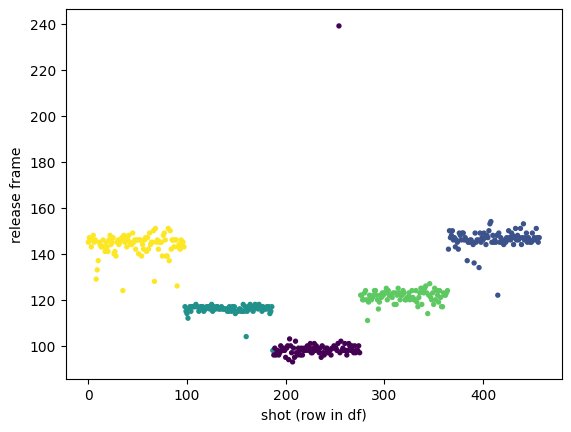

In [ ]:
plot_release_frames()

In [ ]:
find_release_frames_outliers(df)

,sampling_rate,trial_date,participant_id,trial_id,result,landing_x,landing_y,entry_angle,tracking
254,60,2025-12-18,P0001,T0036,missed,0.59,-0.57,46.06,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."


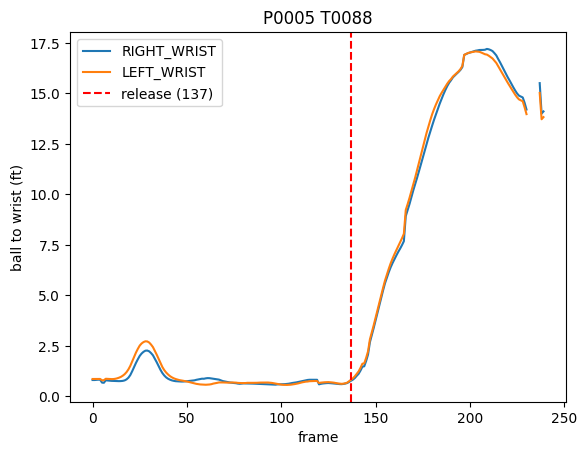

In [ ]:
plot_shot(df.loc[10]) # put any trial